# Notebook 2. One place, many moments

> Readable here as is; to run it, `./scripts/fetch_data.sh` downloads about 2.5 GB.

**The question:** *A lander sits at one spot for a whole year. How much of the time is the Sun up? How long is the longest night? When can it talk to Earth? And on which landing dates would a mission stay within the darkness limit?*

Notebook 1 answered "where are the Sun and Earth, and can we see them?" for **one** moment. A mission lasts weeks. So here we do the same thing for **35 041 moments**, one every 15 minutes through 2027, and then look at *runs* of moments: dark runs, DSN-in-view runs, landing windows.

This follows **Step 5 (visibility, DSN in view and the darkness limit) and Step 6 (many times, many sites)** of the method in the Python reference (`lunazen/`) that the app is checked against.

> **Before you start.** Run `./scripts/fetch_data.sh` once from the project folder. It downloads the data this notebook reads: the SPICE kernels (where the Sun, Earth and Moon are) and the LOLA 20 m terrain map (the heights of the ground). About 2.5 GB in all, and it skips what you already have.

| Part | Question |
|---|---|
| A | Set-up: the same spot and skyline as notebook 1 |
| B | Where are the Sun and Earth, every 15 minutes? |
| C | Is the Sun up? Is Earth up? Can the DSN hear us? |
| D | How long is the longest night? |
| E | Which landing dates work? |

## A. Set-up: the same spot, the same skyline

Nothing new here. These cells are the code of notebook 1, in compact form: load the kernels, read the LOLA 20 m map, trace the skyline. If any line looks strange, notebook 1 explains it.

In [1]:
import os
import numpy as np
import spiceypy as spice
import matplotlib.pyplot as plt

# Colours as in the guides: blue, red, green and gold.
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
                     "axes.prop_cycle": plt.cycler(color=["#1f4e9c", "#c0272d", "#2e8b57", "#f0a30a"]),
                     "axes.titlecolor": "#14357a", "axes.labelcolor": "#14357a"})
np.set_printoptions(precision=4, suppress=True)

# Find the project folder (the one holding scripts/fetch_data.sh), wherever Jupyter was started.
root = os.getcwd()
while not os.path.exists(os.path.join(root, "scripts", "fetch_data.sh")):
    parent = os.path.dirname(root)
    if parent == root:
        raise FileNotFoundError("Run this notebook from inside the project folder.")
    root = parent

# Where the downloaded data lives (scripts/fetch_data.sh puts it here).
DATA = os.path.join(root, "data", "external")
KERNELS = os.path.join(DATA, "kernels")
LOLA = os.path.join(DATA, "lola")
if not (os.path.exists(os.path.join(KERNELS, "de440s.bsp")) and os.path.exists(os.path.join(LOLA, "LDEM_85S_20M.IMG"))):
    raise FileNotFoundError("Data is missing. Run ./scripts/fetch_data.sh from the project folder first.")

In [2]:
LAT_DEG = -89.47485136585945      # planetocentric latitude
LON_DEG = 222.55686188749715      # east longitude
GROUND_M = 1947.36                # height of the ground above the 1737.4 km sphere (the 5 m NASA tile's value; the 20 m map below gives 1947.0)
MAST_M = 2.0                      # antenna / camera height
R_MOON = 1_737_400.0              # lunar reference sphere, metres (matches LOLA)

In [3]:
KERNEL_FILES = {
    "naif0012.tls":          "leap seconds",
    "pck00011.tpc":          "planet sizes and spin (Earth's orientation lives here)",
    "moon_de440_250416.tf":  "names of the Moon's frames, e.g. MOON_ME",
    "moon_pa_de440_200625.bpc": "the Moon's orientation, very accurately",
    "de440s.bsp":            "positions of Sun, Earth, Moon (DE440, 1849 to 2150)",
}
spice.kclear()
for name, what in KERNEL_FILES.items():
    path = os.path.join(KERNELS, name)
    spice.furnsh(path)
    print(f"{name:28s} {os.path.getsize(path)/1e6:8.2f} MB   {what}")

naif0012.tls                     0.01 MB   leap seconds
pck00011.tpc                     0.13 MB   planet sizes and spin (Earth's orientation lives here)
moon_de440_250416.tf             0.02 MB   names of the Moon's frames, e.g. MOON_ME
moon_pa_de440_200625.bpc        12.86 MB   the Moon's orientation, very accurately
de440s.bsp                      32.73 MB   positions of Sun, Earth, Moon (DE440, 1849 to 2150)


In [4]:
label = open(os.path.join(LOLA, "LDEM_85S_20M.LBL"), errors="replace").read()
import re
def lab(key):
    return re.search(rf"^\s*{key}\s*=\s*([^\s<]+)", label, re.M).group(1).strip('"')

N = int(lab("LINES"))
SCALE_M = float(re.search(r"MAP_SCALE\s*=\s*([\d.]+)", label).group(1)) * (1000 if "km" in re.search(r"MAP_SCALE\s*=.*", label).group(0) else 1)
LINE_OFF = float(re.search(r"LINE_PROJECTION_OFFSET\s*=\s*([-\d.]+)", label).group(1))
SAMPLE_OFF = float(re.search(r"SAMPLE_PROJECTION_OFFSET\s*=\s*([-\d.]+)", label).group(1))
FACTOR = float(lab("SCALING_FACTOR"))
print("grid:", N, "x", N, "   pixel size:", SCALE_M, "m   scale:", FACTOR, "m per count")
print("projection offsets (line, sample):", LINE_OFF, SAMPLE_OFF)

# 'memmap' means: do not load 460 MB, just look at the file where we need it.
raw = np.memmap(os.path.join(LOLA, "LDEM_85S_20M.IMG"), dtype="<i2", mode="r", shape=(N, N))
print("height at map centre (the pole):", raw[N // 2, N // 2] * FACTOR, "m")

grid: 15168 x 15168    pixel size: 20.0 m   scale: 0.5 m per count
projection offsets (line, sample): 7583.5 7583.5
height at map centre (the pole): 1288.5 m


In [5]:
def to_xy(lat_rad, lon_rad):
    rho = 2.0 * R_MOON * np.tan((np.pi / 2.0 + lat_rad) / 2.0)
    return rho * np.sin(lon_rad), rho * np.cos(lon_rad)

def to_pixel(x, y):
    # column grows with x, row grows as y falls; the label's offsets already refer to pixel centres
    col = x / SCALE_M + SAMPLE_OFF
    row = LINE_OFF - y / SCALE_M
    return row, col

In [6]:
def height_at(rows, cols):
    rows, cols = np.asarray(rows, float), np.asarray(cols, float)
    r0 = np.floor(rows).astype(int); c0 = np.floor(cols).astype(int)
    a, b = rows - r0, cols - c0
    inside = (r0 >= 0) & (c0 >= 0) & (r0 < N - 1) & (c0 < N - 1)
    r0c, c0c = np.clip(r0, 0, N - 2), np.clip(c0, 0, N - 2)
    z = ((1 - a) * (1 - b) * raw[r0c, c0c] + (1 - a) * b * raw[r0c, c0c + 1]
         + a * (1 - b) * raw[r0c + 1, c0c] + a * b * raw[r0c + 1, c0c + 1]) * FACTOR
    return np.where(inside, z, np.nan)

In [7]:
r0_, c0_ = to_pixel(*to_xy(np.radians(LAT_DEG), np.radians(LON_DEG)))
GROUND_M = float(height_at(r0_, c0_))
lat, lon = np.radians(LAT_DEG), np.radians(LON_DEG)
east  = np.array([-np.sin(lon), np.cos(lon), 0.0])
north = np.array([-np.sin(lat) * np.cos(lon), -np.sin(lat) * np.sin(lon), np.cos(lat)])
up    = np.array([ np.cos(lat) * np.cos(lon),  np.cos(lat) * np.sin(lon), np.sin(lat)])
site = (R_MOON + GROUND_M + MAST_M) * up
print(f"ground height {GROUND_M:.1f} m, antenna at {np.linalg.norm(site)/1000:.3f} km from the Moon's centre")

ground height 1947.0 m, antenna at 1739.349 km from the Moon's centre


In [8]:
def destination(lat_r, lon_r, az_r, delta):
    lat2 = np.arcsin(np.sin(lat_r) * np.cos(delta) + np.cos(lat_r) * np.sin(delta) * np.cos(az_r))
    lon2 = lon_r + np.arctan2(np.sin(az_r) * np.sin(delta) * np.cos(lat_r),
                              np.cos(delta) - np.sin(lat_r) * np.sin(lat2))
    return lat2, lon2

def distances(min_m=10.0, max_m=300_000.0, step_min=5.0, k=400.0):
    out, s = [], min_m
    while s <= max_m:
        out.append(s); s += max(step_min, s / k)
    return np.array(out)

S = distances()
print(len(S), "steps along each ray, from", S[0], "m to", S[-1], "m")

2405 steps along each ray, from 10.0 m to 299432.4528086353 m


In [9]:
r0_obs = R_MOON + GROUND_M + MAST_M

def elevation_profile(az_deg):
    delta = S / R_MOON
    la, lo = destination(lat, lon, np.radians(az_deg), delta)
    rr, cc = to_pixel(*to_xy(la, lo))
    z = height_at(rr, cc)                     # NaN where the ray leaves the map
    r1 = R_MOON + z
    eps = np.degrees(np.arctan2(r1 * np.cos(delta) - r0_obs, r1 * np.sin(delta)))
    return z, eps

In [10]:
AZ = np.arange(0.0, 360.0, 0.25)
HORIZON = np.empty_like(AZ)
for i, a in enumerate(AZ):
    HORIZON[i] = np.nanmax(elevation_profile(a)[1])

def horizon_at(a):
    # linear interpolation, wrapping around 360 degrees
    return np.interp(np.asarray(a) % 360.0, np.append(AZ, 360.0), np.append(HORIZON, HORIZON[0]))

In [11]:
# Horizon lookup: linear interpolation, wrapping at 360 degrees.
def horizon_at(a):
    return np.interp(np.asarray(a) % 360.0, np.append(AZ, 360.0), np.append(HORIZON, HORIZON[0]))
print(f"skyline: {HORIZON.min():.2f} to {HORIZON.max():.2f} deg")

skyline: -2.85 to 0.66 deg


## B. Where are the Sun and Earth, every 15 minutes?

### The time grid
A year has $365\times 24\times 4 = 35\,040$ quarter-hours, plus the last instant. Why 15 minutes? Short enough to catch a brief gap behind a ridge, and the handover between antenna complexes. An hourly step would smooth those away. (It is called `STEP_S` in the app.)

`spice.str2et` turns the start into ET. After that, time is just arithmetic: add 900 s again and again.

In [12]:
STEP_S = 900.0
et0 = spice.str2et("2027-01-01T00:00:00")
et1 = spice.str2et("2028-01-01T00:00:00")
N = int(round((et1 - et0) / STEP_S)) + 1
ets = et0 + STEP_S * np.arange(N)
print(N, "moments, from", spice.et2utc(ets[0], "ISOC", 0), "to", spice.et2utc(ets[-1], "ISOC", 0))

35041 moments, from 2027-01-01T00:00:00 to 2028-01-01T00:00:00


### Many positions in one call
`spkpos` accepts a whole array of times. We ask once for all 35 041 Sun vectors and once for all Earth vectors, in MOON_ME, with light time and aberration (`"LT+S"`) as before. Then azimuth and elevation work on every row at once: the same formulas as notebook 1 with the dot products done for a whole table.

In [13]:
def positions(body):
    pos_km, _ = spice.spkpos(body, ets, "MOON_ME", "LT+S", "MOON")
    return np.array(pos_km) * 1000.0           # metres, shape (N, 3)

def az_el_series(vectors):
    v = vectors - site                          # from the antenna, not the Moon's centre
    e, n, u = v @ east, v @ north, v @ up
    return (np.degrees(np.arctan2(e, n)) % 360.0,
            np.degrees(np.arctan2(u, np.hypot(e, n))),
            np.linalg.norm(v, axis=1))

SUN_RADIUS_M, EARTH_RADIUS_M = 695_700_000.0, 6_378_137.0
sun_az, sun_el, sun_dist = az_el_series(positions("SUN"))
earth_az, earth_el, earth_dist = az_el_series(positions("EARTH"))
sun_rad = np.degrees(np.arcsin(SUN_RADIUS_M / sun_dist))
earth_rad = np.degrees(np.arcsin(EARTH_RADIUS_M / earth_dist))
print(f"Sun elevation over the year:   {sun_el.min():6.2f} to {sun_el.max():5.2f} deg")
print(f"Earth elevation over the year: {earth_el.min():6.2f} to {earth_el.max():5.2f} deg")

Sun elevation over the year:    -2.05 to  2.04 deg
Earth elevation over the year:  -7.53 to  6.23 deg


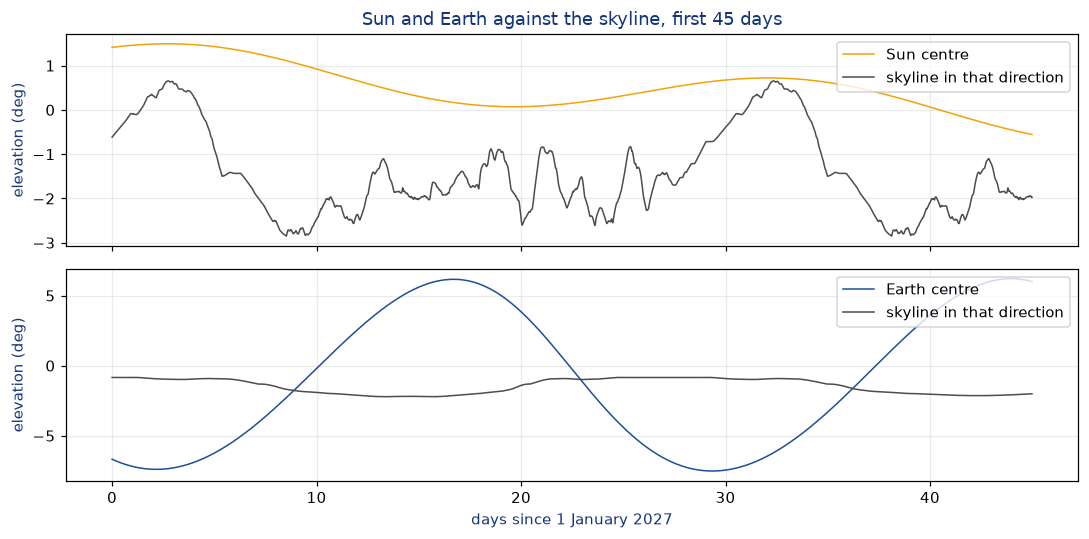

In [14]:
days = (ets - et0) / 86400.0
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
sel = days < 45                                  # first 45 days, like the User Guide's figure
for ax, el, az, rad, col, name in ((axes[0], sun_el, sun_az, sun_rad, "#f0a30a", "Sun"),
                                   (axes[1], earth_el, earth_az, earth_rad, "#1f4e9c", "Earth")):
    ax.plot(days[sel], el[sel], color=col, lw=1, label=f"{name} centre")
    ax.plot(days[sel], horizon_at(az[sel]), color="0.3", lw=1, label="skyline in that direction")
    ax.set_ylabel("elevation (deg)"); ax.legend(loc="upper right")
axes[1].set_xlabel("days since 1 January 2027")
axes[0].set_title("Sun and Earth against the skyline, first 45 days");
fig.tight_layout()

The Sun rises and sets a little each *lunar day* (about 29.5 Earth days). It grazes the skyline: when its centre dips under the grey line the disk may still peek out. The Earth swings slowly up and down with the Moon's libration (the nodding from notebook 1) and the monthly orbit.

## C. Is the Sun up? Is Earth up? Can the DSN hear us?

### Visible fraction, for every moment
Same idea as notebook 1: slice each disk into 64 columns and count what clears the skyline. The only change is that every row of the table is a moment, so we compute 64 columns for all 35 041 moments together.

A body is **up when its visible fraction is above 0**.

In [15]:
def visible_fraction(az, el, radius, columns=64):
    u = -1.0 + (np.arange(columns) + 0.5) * (2.0 / columns)         # column centres, in radii
    half = radius[:, None] * np.sqrt(1.0 - u**2)[None, :]           # half-height of each column
    cols_az = az[:, None] + radius[:, None] * u[None, :] / np.cos(np.radians(el))[:, None]
    terrain = horizon_at(cols_az)
    top, bottom = el[:, None] + half, el[:, None] - half
    seen = np.clip(top - np.maximum(bottom, terrain), 0.0, None)
    return seen.sum(axis=1) / (2.0 * half).sum(axis=1)

sun_f = visible_fraction(sun_az, sun_el, sun_rad)
earth_f = visible_fraction(earth_az, earth_el, earth_rad)
sunlit, earth_up = sun_f > 0, earth_f > 0
print(f"Sun up    {sunlit.mean()*100:5.1f} % of the year")
print(f"Earth up  {earth_up.mean()*100:5.1f} % of the year")
print(f"Both up   {(sunlit & earth_up).mean()*100:5.1f} % of the year")

Sun up     89.7 % of the year
Earth up   55.2 % of the year
Both up    49.4 % of the year


### How much light?
"Up or down" is a yes-or-no answer. For an amount, imagine a solar array that stands upright and turns to face the Sun, so the angle between sunlight and the panel is just the Sun's elevation $E$. A 1 W array then collects, over the year,

$$\text{energy}=\sum_k f_{\odot,k}\,\max(0,\cos E_k)\,\Delta t \quad (\text{Wh per W of array}).$$

An array lying flat would use $\sin E$ instead, and at the pole $E$ is tiny. This measures *light*, not any lander: no battery, no load.

In [16]:
step_h = STEP_S / 3600.0
upright = (sun_f * np.clip(np.cos(np.radians(sun_el)), 0, None)).sum() * step_h
flat = (sun_f * np.clip(np.sin(np.radians(sun_el)), 0, None)).sum() * step_h
print(f"upright array facing the Sun: {upright:7.0f} Wh per W over 2027")
print(f"array lying flat            : {flat:7.0f} Wh per W  ({flat / upright * 100:.1f} % of the upright one)")

upright array facing the Sun:    7463 Wh per W over 2027
array lying flat            :      80 Wh per W  (1.1 % of the upright one)


### How long until sunset or Earthset?
Mission operators ask: *how long until the Sun or Earth goes behind the terrain, and how long until it comes back?* Standing at one sample, walk forward until the yes-or-no answer flips. The app's Explorer shows exactly this under its Sun and Earth readouts (`timeToChange` in the browser, `time_to_change` in Python, both on the same 15-minute grid).

In [17]:
def hours_to_change(flag, k):
    flips = np.nonzero(flag[k:] != flag[k])[0]
    return flips[0] * STEP_S / 3600.0 if flips.size else None

k_now = int(round((spice.str2et("2027-03-01T06:15:00") - et0) / STEP_S))
for body, flag in (("Sun", sunlit), ("Earth", earth_up)):
    wait = hours_to_change(flag, k_now)
    action = "sets behind the terrain" if flag[k_now] else "rises above the terrain"
    state = "up" if flag[k_now] else "hidden"
    print(f"1 March 2027, 06:15 UTC: {body} is {state}; it {action} in {wait:.2f} h" if wait is not None else f"{body}: no change this year")

1 March 2027, 06:15 UTC: Sun is up; it sets behind the terrain in 36.75 h
1 March 2027, 06:15 UTC: Earth is hidden; it rises above the terrain in 90.25 h


### Is the DSN looking at the Moon?
Same recipe as notebook 1, for all moments at once: the Moon's vector from Earth in `IAU_EARTH`, minus each dish, projected on that dish's local vertical (the WGS84 normal).

In [18]:
DSN = {   # NASA/JPL DSN 810-005 Module 301, Earth-fixed Cartesian coordinates, metres
    "Goldstone (DSS-14)": np.array([-2353621.420, -4641341.472,  3677052.318]),
    "Canberra (DSS-43)":  np.array([-4460894.917,  2682361.507, -3674748.152]),
    "Madrid (DSS-63)":    np.array([ 4849092.518,  -360180.348,  4115109.251]),
}

In [19]:
A_WGS, F_WGS = 6378137.0, 1.0 / 298.257223563

def geodetic_up(xyz):
    x, y, z = xyz
    e2 = F_WGS * (2 - F_WGS)
    p = np.hypot(x, y)
    phi = np.arctan2(z, p * (1 - e2))
    for _ in range(5):
        n = A_WGS / np.sqrt(1 - e2 * np.sin(phi) ** 2)
        h = p / np.cos(phi) - n
        phi = np.arctan2(z, p * (1 - e2 * n / (n + h)))
    lam = np.arctan2(y, x)
    return np.array([np.cos(phi) * np.cos(lam), np.cos(phi) * np.sin(lam), np.sin(phi)]), np.degrees(phi), np.degrees(lam)

In [20]:
MASK_DEG = 10.0
moon_km, _ = spice.spkpos("MOON", ets, "IAU_EARTH", "LT+S", "EARTH")
moon_e = np.array(moon_km) * 1000.0
dsn_el = {}
for name, xyz in DSN.items():
    v = moon_e - xyz
    dsn_el[name] = np.degrees(np.arcsin((v @ geodetic_up(xyz)[0]) / np.linalg.norm(v, axis=1)))
complex_sees = np.any([e > MASK_DEG for e in dsn_el.values()], axis=0)
link = earth_up & complex_sees
print(f"A DSN complex sees the Moon        {complex_sees.mean()*100:5.1f} % of the year")
print(f"Earth up at the spot               {earth_up.mean()*100:5.1f} %")
print(f"Earth up AND a complex sees it     {link.mean()*100:5.1f} %   <- DSN in view")

A DSN complex sees the Moon         98.0 % of the year
Earth up at the spot                55.2 %
Earth up AND a complex sees it      54.8 %   <- DSN in view


Look at those three numbers. The DSN almost always sees the Moon: the three complexes are spread around the world. What cuts DSN in view is the *lander's own skyline*. At the pole, mountains, not antennas, limit contact.

### Runs: windows and gaps
A *window* is a stretch of consecutive moments where the answer is yes. We find each stretch by looking at where the yes/no series *changes*.

In [21]:
def runs(mask):
    # (start_index, end_index_exclusive) of each stretch of True values
    edges = np.flatnonzero(np.diff(np.concatenate(([0], mask.astype(np.int8), [0]))))
    return list(zip(edges[::2], edges[1::2]))

def longest_hours(mask):
    r = runs(mask)
    return max((b - a for a, b in r), default=0) * STEP_S / 3600.0

print(f"longest stretch without Earth in view   : {longest_hours(~earth_up):6.1f} h")
print(f"longest stretch without DSN in view     : {longest_hours(~link):6.1f} h")
print(f"number of separate DSN-in-view windows  : {len(runs(link))}")

longest stretch without Earth in view   :  293.5 h
longest stretch without DSN in view     :  293.5 h
number of separate DSN-in-view windows  : 116


## D. How long is the longest night?

This is the question everything else serves. Whether a lander lives through darkness depends on its battery, heaters, load and the cold, and landers hardly ever publish those. They *do* publish how long they lasted (or were designed to last) in the dark, and we use two such figures as darkness limits:

| Darkness limit | Source |
|---|---|
| 5 h (Blue Ghost 1, flew) | NASA, 2025: "continued operations for five hours after lunar sunset" |
| 50 h (VIPER's design figure; VIPER was a rover meant to move to sunlit areas) | NASA: "cannot endure more than 50 hours of continuous darkness" |

So we **do not invent a lander**. We find the *longest* stretch with no part of the Sun above the skyline, $T_\text{dark}^{\max}$, and compare it with a limit:

$$
\text{within the limit} \iff T^{\max}_\text{dark} \le T_\text{limit}.
$$

In [22]:
dark = runs(~sunlit)
dark_hours = np.array([(b - a) * STEP_S / 3600.0 for a, b in dark])
print(f"The Sun is up {sunlit.mean()*100:.1f} % of the year.")
print(f"There are {len(dark)} separate dark stretches.")
print(f"Longest night: {dark_hours.max():.0f} h")
for name, limit in (("5 h (Blue Ghost 1)", 5.0), ("50 h (VIPER's design figure)", 50.0)):
    print(f"  {name:28s} ->  {'within the limit' if dark_hours.max() <= limit else 'NOT within the limit'}"
          f"   ({dark_hours.max()/limit:.1f} x the limit)")

The Sun is up 89.7 % of the year.
There are 28 separate dark stretches.
Longest night: 138 h
  5 h (Blue Ghost 1)           ->  NOT within the limit   (27.6 x the limit)
  50 h (VIPER's design figure) ->  NOT within the limit   (2.8 x the limit)


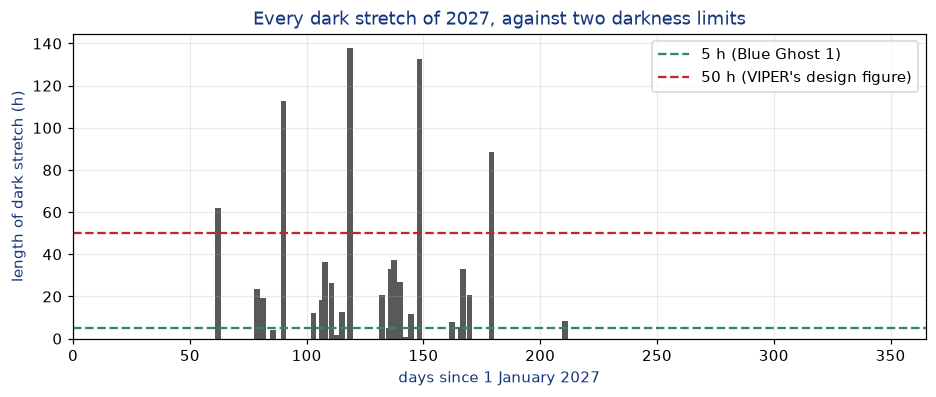

In [23]:
fig, ax = plt.subplots(figsize=(10, 3.6))
starts = np.array([a for a, b in dark]) * STEP_S / 86400.0
ax.bar(starts, dark_hours, width=2.5, color="0.35", align="edge")
ax.axhline(5, color="#2e8b57", ls="--", label="5 h (Blue Ghost 1)")
ax.axhline(50, color="#c0272d", ls="--", label="50 h (VIPER's design figure)")
ax.set_xlim(0, 365); ax.set_xlabel("days since 1 January 2027"); ax.set_ylabel("length of dark stretch (h)")
ax.set_title("Every dark stretch of 2027, against two darkness limits"); ax.legend();

The Sun is up most of the year, which sounds generous. But the one number that matters is the *longest* night. An average hides it.

> **Try it.** Change `MAST_M` at the top to 10 and run everything again (**Run all**). A higher antenna sees over more terrain. How much does the longest night shrink?

## E. Which landing dates work?

A mission planner asks the reverse question: *if we land at time $T$ and must work for $N$ days, will the longest night stay within the darkness limit?*

For each possible landing time (a new one every **6 hours**) we take the next $N = 14$ days and find:

* the longest dark stretch inside them, and
* the share of those days with DSN in view.

A landing is **good** when the longest dark stretch is within the darkness limit (we use 50 h, VIPER's design figure; VIPER was a rover meant to move to sunlit areas) **and** the DSN share is at least 50 %.

In [24]:
MISSION_DAYS, DARK_TOL_H, LINK_MIN = 14, 50.0, 0.50
n_mission = int(MISSION_DAYS * 86400 / STEP_S)
stride = int(6 * 3600 / STEP_S)                  # a new landing every 6 hours

# The last landings need 14 more days of Sun and Earth after 2027, so compute that tail and join it to the year.
ets_tail = et0 + STEP_S * np.arange(N, N + n_mission)
def series(ets_arr):
    s_az, s_el, s_d = az_el_series(np.array(spice.spkpos("SUN", ets_arr, "MOON_ME", "LT+S", "MOON")[0]) * 1000.0)
    e_az, e_el, e_d = az_el_series(np.array(spice.spkpos("EARTH", ets_arr, "MOON_ME", "LT+S", "MOON")[0]) * 1000.0)
    sf = visible_fraction(s_az, s_el, np.degrees(np.arcsin(SUN_RADIUS_M / s_d)))
    ef = visible_fraction(e_az, e_el, np.degrees(np.arcsin(EARTH_RADIUS_M / e_d)))
    m = np.array(spice.spkpos("MOON", ets_arr, "IAU_EARTH", "LT+S", "EARTH")[0]) * 1000.0
    sees = np.any([np.degrees(np.arcsin(((m - x) @ geodetic_up(x)[0]) / np.linalg.norm(m - x, axis=1))) > MASK_DEG
                   for x in DSN.values()], axis=0)
    return sf > 0, (ef > 0) & sees

tail_sun, tail_link = series(ets_tail)
sun_x, link_x = np.concatenate([sunlit, tail_sun]), np.concatenate([link, tail_link])

good = []
for start in range(0, N, stride):
    w = slice(start, start + n_mission)
    longest_dark = max((b - a for a, b in runs(~sun_x[w])), default=0) * STEP_S / 3600.0
    good.append(longest_dark <= DARK_TOL_H and link_x[w].mean() >= LINK_MIN)
good = np.array(good)
print(f"{len(good)} possible landing times in 2027 (every 6 h)")
print(f"{good.sum()} are good ({good.mean()*100:.0f} %): dark stretch within {DARK_TOL_H:.0f} h and DSN in view at least {LINK_MIN*100:.0f} %")

1461 possible landing times in 2027 (every 6 h)
625 are good (43 %): dark stretch within 50 h and DSN in view at least 50 %


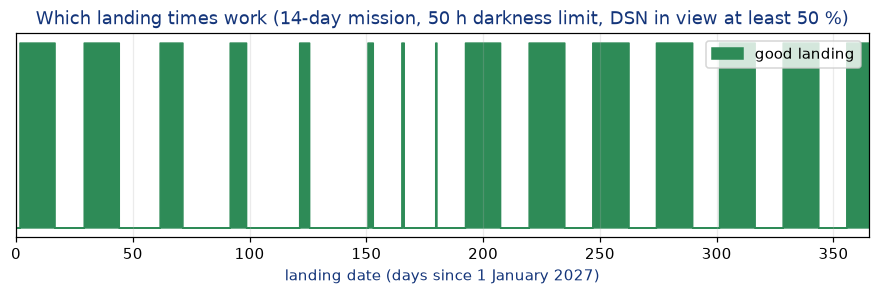

In [25]:
t_days = np.arange(len(good)) * 6 / 24.0
fig, ax = plt.subplots(figsize=(10, 2.4))
ax.fill_between(t_days, 0, good, step="post", color="#2e8b57", label="good landing")
ax.set_yticks([]); ax.set_xlabel("landing date (days since 1 January 2027)")
ax.set_title("Which landing times work (14-day mission, 50 h darkness limit, DSN in view at least 50 %)")
ax.set_xlim(0, 365); ax.legend(loc="upper right");

Green bands are landing windows: a week or two at a time, whenever the long nights fall outside the mission. Real landers miss their target. The app repeats this test at twelve more points around the spot (six at 50 m, six at 100 m), and counts a day as working *within 100 m* only if some landing is good at all thirteen points. A hundred metres can matter more than a month.

## Check and limits

* The numbers above use only the LOLA 20 m map and one point (the spot). The app uses a 5 m tile near the spot too, so its numbers differ slightly: the User Guide quotes 89.7 % sunlit and a 138 h longest night, and 43 % good landings. This notebook gets 89.7 %, 138 h and 43 % too. It finds 28 dark stretches where the User Guide counts 29, and 625 good landings where the app finds 628. The small differences most likely come from the map (no 5 m tile here); we did not chase the single missing stretch.
* Time grid: 15 minutes. A gap shorter than that can be missed.
* DSN: SPICE's simple Earth-spin model, about a minute of error at an edge of DSN in view. No weather or scheduling.
* There is no battery or power model anywhere. A lander is judged only against a darkness limit.

**Next:** the browser engine in `web/engine/` repeats these steps in JavaScript, with the ephemeris as a stored table, precomputed skylines and Web Workers; its tests hold it to the Python reference.